<a href="https://colab.research.google.com/github/Alfonsotomax/Adfonfin/blob/main/data/setup_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Downloading the photos from the datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/dog-project-data'
!ls {DATA_DIR}

In [ ]:
!wget -P {DATA_DIR} https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget -P {DATA_DIR} https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz

In [ ]:
!wget -O {DATA_DIR}/thudogs-low-res.zip https://cloud.tsinghua.edu.cn/f/80013ef29c5f42728fc8/?dl=1
!wget -P {DATA_DIR} https://cg.cs.tsinghua.edu.cn/ThuDogs/low-annotations.zip
!wget -P {DATA_DIR} https://cg.cs.tsinghua.edu.cn/ThuDogs/TrainValSplit.zip

In [ ]:
!wget -O {DATA_DIR}/mendeley.zip https://data.mendeley.com/public-api/zip/v5j6m8dzhv/download/1

# Extarct archives to Colab's local disk

In [6]:
import pathlib, zipfile, collections

RAW_DIR = '/content/raw'
!mkdir -p {RAW_DIR}/oxford {RAW_DIR}/thudogs {RAW_DIR}/mendeley
!tar -xzf {DATA_DIR}/images.tar.gz -C {RAW_DIR}/oxford
!tar -xzf {DATA_DIR}/annotations.tar.gz -C {RAW_DIR}/oxford
!unzip -q -o {DATA_DIR}/thudogs-low-res.zip -d {RAW_DIR}/thudogs
!unzip -q -o {DATA_DIR}/low-annotations.zip -d {RAW_DIR}/thudogs
!unzip -q -o {DATA_DIR}/mendeley.zip -d {RAW_DIR}/mendeley

# Mendeley's zip can contain nested zips
for z in pathlib.Path(RAW_DIR, 'mendeley').rglob('*.zip'):
    zipfile.ZipFile(z).extractall(z.parent)

In [7]:
!find {RAW_DIR} -maxdepth 3 -type d | head -40

for name in ['oxford', 'thudogs', 'mendeley']:
    exts = collections.Counter(f.suffix.lower() for f in pathlib.Path(RAW_DIR, name).rglob('*') if f.is_file())
    print(name, exts.most_common(6))

xmls = list(pathlib.Path(RAW_DIR, 'thudogs').rglob('*.xml'))
print(len(xmls), 'Tsinghua annotation files')
if xmls:
    print(xmls[0])
    print(xmls[0].read_text(errors='ignore')[:1500])

/content/raw
/content/raw/oxford
/content/raw/oxford/annotations
/content/raw/oxford/annotations/xmls
/content/raw/oxford/annotations/trimaps
/content/raw/oxford/images
/content/raw/thudogs
/content/raw/thudogs/low-resolution
/content/raw/thudogs/low-resolution/3336-n000121-chinese_rural_dog
/content/raw/thudogs/low-resolution/211-n000052-Dandie_Dinmont
/content/raw/thudogs/low-resolution/203-n000016-Norwich_terrier
/content/raw/thudogs/low-resolution/420-n000124-Chihuahua
/content/raw/thudogs/low-resolution/5355-n000126-golden_retriever
/content/raw/thudogs/low-resolution/206-n000035-Great_Dane
/content/raw/thudogs/low-resolution/243-n000103-basenji
/content/raw/thudogs/low-resolution/209-n000054-Doberman
/content/raw/thudogs/low-resolution/211-n000009-cairn
/content/raw/thudogs/low-resolution/286-n000111-cocker_spaniel
/content/raw/thudogs/low-resolution/241-n000100-basset
/content/raw/thudogs/low-resolution/276-n000113-beagle
/content/raw/thudogs/low-resolution/480-n000125-Pekinese


In [8]:
import re
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
from PIL import Image
from multiprocessing import Pool
from tqdm.auto import tqdm

IMG_SIZE = 64
PAD = 0.10       # padding around the bounding box, as a fraction of its size
MIN_SIDE = 48    # skip crops smaller than this (pixels); they upscale to mush
IMG_EXTS = {'.jpg', '.jpeg', '.png'}


def square_crop(img, box=None):
    """Crop a padded square around box (x0, y0, x1, y1), or the center if box is None, and resize."""
    W, H = img.size
    x0, y0, x1, y1 = box if box is not None else (0, 0, W, H)
    x0, y0, x1, y1 = max(x0, 0), max(y0, 0), min(x1, W), min(y1, H)
    if x1 <= x0 or y1 <= y0:
        return None
    side = min(max(x1 - x0, y1 - y0) * (1 + 2 * PAD), W, H)
    if side < MIN_SIDE:
        return None
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    left = min(max(cx - side / 2, 0), W - side)
    top = min(max(cy - side / 2, 0), H - side)
    crop = img.crop((round(left), round(top), round(left + side), round(top + side)))
    return crop.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)


def oxford_box(stem):
    tri = pathlib.Path(RAW_DIR, 'oxford/annotations/trimaps', stem + '.png')
    if not tri.exists():
        return None
    ys, xs = np.nonzero(np.asarray(Image.open(tri)) != 2)  # 1 = pet, 2 = background, 3 = border
    if len(xs) == 0:
        return None
    return (xs.min(), ys.min(), xs.max() + 1, ys.max() + 1)


def thudogs_box(ann_path):
    boxes = []
    for el in ET.parse(ann_path).getroot().iter():
        coords = [el.find(k) for k in ('xmin', 'ymin', 'xmax', 'ymax')]
        if all(c is not None for c in coords):
            boxes.append(tuple(float(c.text) for c in coords))
    if not boxes:
        return None
    return max(boxes, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))


def process(job):
    """Returns (array, source, path) on success or (None, source, reason) if skipped."""
    source, path, ann_path = job
    try:
        img = Image.open(path).convert('RGB')
        if source == 'oxford':
            box = oxford_box(path.stem)
        elif source == 'thudogs':
            if ann_path is None:
                return None, source, 'no annotation'
            box = thudogs_box(ann_path)
            if box is None:
                return None, source, 'no box in annotation'
        else:
            box = None
    except Exception:
        return None, source, 'unreadable'
    out = square_crop(img, box)
    if out is None:
        return None, source, 'too small'
    arr = np.asarray(out)
    rg = np.abs(arr[..., 0].astype(int) - arr[..., 1]).mean()
    gb = np.abs(arr[..., 1].astype(int) - arr[..., 2]).mean()
    if rg < 2 and gb < 2:
        return None, source, 'grayscale'
    return arr, source, str(pathlib.Path(path).relative_to(RAW_DIR))

In [9]:
def ann_key(p):
    # Low-Annotations/<breed>/n147324.jpeg.xml -> (<breed>, n147324)
    return p.parent.name, re.sub(r'(\.jpe?g|\.png)?\.xml$', '', p.name, flags=re.I)

jobs = []
for p in pathlib.Path(RAW_DIR, 'oxford/images').glob('*.jpg'):
    if p.name[0].islower():  # dog breeds are lowercase, cat breeds are Capitalized
        jobs.append(('oxford', p, None))

ann = {ann_key(p): p for p in pathlib.Path(RAW_DIR, 'thudogs').rglob('*.xml')}
for p in pathlib.Path(RAW_DIR, 'thudogs').rglob('*'):
    if p.suffix.lower() in IMG_EXTS:
        jobs.append(('thudogs', p, ann.get((p.parent.name, p.stem))))

for p in pathlib.Path(RAW_DIR, 'mendeley').rglob('*'):
    if p.suffix.lower() in IMG_EXTS:
        jobs.append(('mendeley', p, None))

print(collections.Counter(j[0] for j in jobs))
print('Tsinghua images missing an annotation:', sum(1 for j in jobs if j[0] == 'thudogs' and j[2] is None))

Counter({'thudogs': 70432, 'oxford': 4990, 'mendeley': 1657})
Tsinghua images missing an annotation: 4


In [10]:
with Pool() as pool:
    results = list(tqdm(pool.imap(process, jobs, chunksize=64), total=len(jobs)))

kept = [r for r in results if r[0] is not None]
skipped = collections.Counter((r[1], r[2]) for r in results if r[0] is None)
print('kept:', collections.Counter(r[1] for r in kept))
print('skipped:', skipped)

  0%|          | 0/77079 [00:00<?, ?it/s]

kept: Counter({'thudogs': 70178, 'oxford': 4942, 'mendeley': 1644})
skipped: Counter({('thudogs', 'grayscale'): 250, ('oxford', 'grayscale'): 48, ('mendeley', 'too small'): 11, ('thudogs', 'no annotation'): 4, ('mendeley', 'grayscale'): 2})


In [11]:
def ahash(arr):
    g = np.asarray(Image.fromarray(arr).convert('L').resize((8, 8), Image.BILINEAR))
    return np.packbits(g > g.mean()).tobytes()

seen, unique = set(), []
for r in kept:
    h = ahash(r[0])
    if h not in seen:
        seen.add(h)
        unique.append(r)
print(f'removed {len(kept) - len(unique)} duplicates, {len(unique)} images left')

removed 477 duplicates, 76287 images left


In [12]:
OUT_DIR = f'{DATA_DIR}/processed'
!mkdir -p {OUT_DIR}

images = np.stack([r[0] for r in unique])  # (N, 64, 64, 3) uint8
meta = pd.DataFrame({'source': [r[1] for r in unique], 'path': [r[2] for r in unique]})

N = len(images)
n_holdout = int(0.025 * N)
perm = np.random.default_rng(42).permutation(N)
meta['split'] = 'train'
meta.loc[perm[:n_holdout], 'split'] = 'val'
meta.loc[perm[n_holdout:2 * n_holdout], 'split'] = 'test'

np.save(f'{OUT_DIR}/dogs64.npy', images)
meta.to_csv(f'{OUT_DIR}/metadata.csv', index_label='idx')
print(images.shape, f'{images.nbytes / 1e6:.0f} MB')
print(pd.crosstab(meta['source'], meta['split']))

(76287, 64, 64, 3) 937 MB
split     test  train   val
source                     
mendeley    44   1545    42
oxford     114   4707   110
thudogs   1749  66221  1755


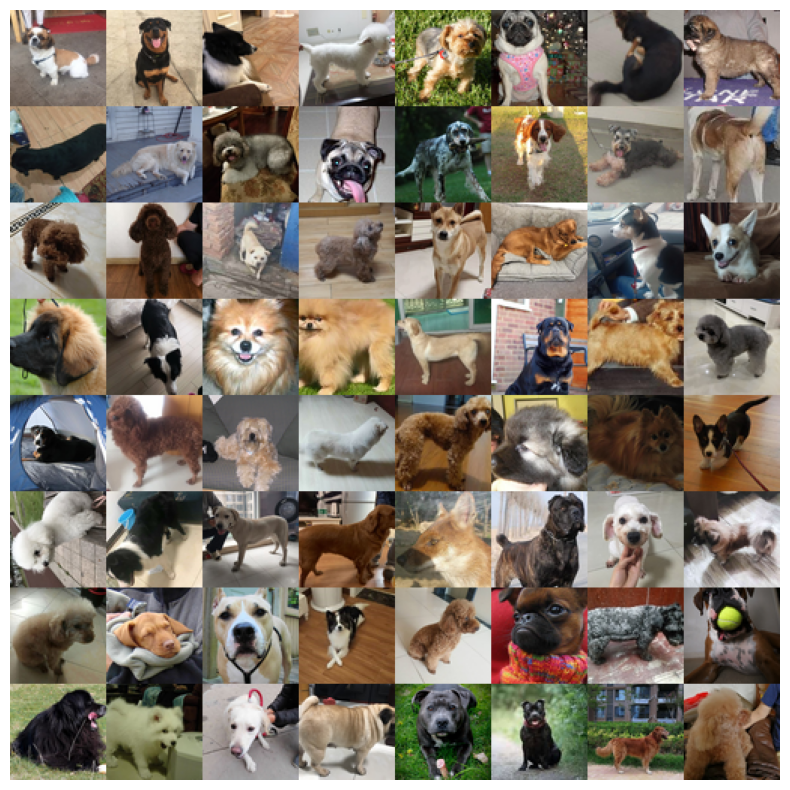

In [13]:
import matplotlib.pyplot as plt

idx = np.random.default_rng(0).choice(N, 64, replace=False)
grid = images[idx].reshape(8, 8, IMG_SIZE, IMG_SIZE, 3).transpose(0, 2, 1, 3, 4).reshape(8 * IMG_SIZE, 8 * IMG_SIZE, 3)
plt.figure(figsize=(10, 10))
plt.imshow(grid)
plt.axis('off')
plt.show()